# Piece 6 — Virtual facilities and data-driven test procedures

Procedures are YAML files in `procedures/`; `core.procedures.run_procedure` validates a file (unknown keys, missing or empty evidence, plot-only values, unit mismatches), runs it in a virtual facility (`core.chamber`) and returns a `TestResult`: measured values with sensor uncertainty, pass/fail per criterion, every evidence ID used, and every assumption and user-defined value.

> **Verification-only inputs.** Many evidence rows needed here (chamber capacity, sensor accuracy, EN 13129 criteria, coach geometry) are still **empty assumptions**. To run the procedures at all, this notebook fills them with the labelled stand-in values in `tests/data/verification_overrides.yaml` (label *verification-only*), and uses the verification unit card. The results show that the machinery works — **they say nothing about a real coach, unit or facility.** Every stand-in value is listed in each TestResult.

In [1]:
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))

import numpy as np
import yaml
import matplotlib.pyplot as plt
from core.chamber import VehicleChamber
from core.coach import load_coach_definition
from core.procedures import ProcedureError, run_procedure
from core.sensors import SensorSet
from core.unit import load_unit_card
from evidence.registry import Registry

# Without stand-in values the runner refuses and says exactly what is missing:
try:
    run_procedure("pulldown_cooling")
except ProcedureError as e:
    print(str(e)[:900], "\n  ...")

procedure 'Pull-down (cooling)' is invalid:
  - stability.window: E-072 (Comfort / soak stability window) has an EMPTY value (status assumption); fill it in evidence.csv
  - stability.max_drift: E-073 (Comfort / soak stability criterion (max cabin drift)) has an EMPTY value (status assumption); fill it in evidence.csv
  - steps[0].set_conditions.chamber_RH: E-071 (Chamber relative humidity for cooling tests (pull-down / comfort)) has an EMPTY value (status assumption); fill it in evidence.csv
  - steps[0].set_conditions.solar.intensity: E-077 (EN 13129 solar intensity, zone I) has an EMPTY value (status assumption); fill it in evidence.csv
  - steps[0].set_conditions.solar.vertical_factor: E-079 (EN 13129 solar factor for vertical surfaces) has an EMPTY value (status assumption); fill it in evidence.csv
  - steps[0].set_conditions.solar.absorptance: E-030 (Opaque surface solar absorptanc 
  ...


In [2]:
overrides = yaml.safe_load((root / "tests/data/verification_overrides.yaml").read_text())
reg = Registry().with_overrides(overrides, label="verification-only")
coach = load_coach_definition(evidence=reg)
card = load_unit_card(root / "tests/data/verification_unit.yaml")
chamber = VehicleChamber.from_evidence(reg)
SEED = 0


def plot(res, band, band_label, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sensors = SensorSet.from_evidence(reg, seed=SEED)
    for k, seg in enumerate(res.segments):
        d = seg.df
        h = d["t_abs_s"] / 3600
        ax.plot(h, d["T_C"], color="tab:blue", label="cabin" if k == 0 else None)
        ax.plot(h, chamber.measured_temperature(d["T_chamber_C"].to_numpy(), sensors),
                color="tab:red", label="chamber (8-probe mean)" if k == 0 else None)
        ax.axvline(h.iloc[0], color="grey", lw=0.6, ls=":")
        ax.text(h.iloc[0], ax.get_ylim()[1] if k else 46, f" {seg.step.split('.')[1]}",
                fontsize=8, va="top", color="grey")
    lo, hi = band
    ax.axhspan(lo, hi, color="tab:green", alpha=0.15, label=band_label)
    ax.set_xlabel("time [h]"); ax.set_ylabel("temperature [°C]"); ax.set_title(title)
    ax.legend(loc="center right"); plt.tight_layout(); plt.show()

## Pull-down (`procedures/pulldown_cooling.yaml`)

Soak at E-022 (45 °C) with the EN 13129 solar load (E-077 roof, × E-079 on the side) until stable, then the unit at full load until the cabin is within E-068 ± E-069; pass if that takes at most E-070. The pass band is the setpoint ± tolerance (verification-only values 27 ± 1 °C).

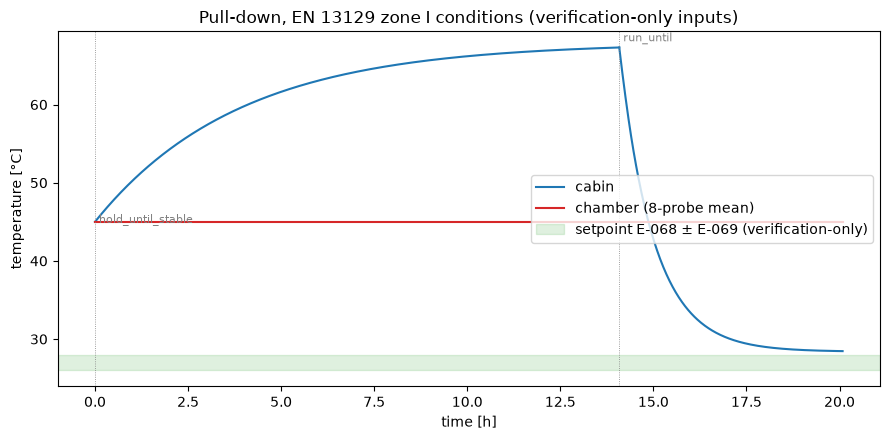

Pull-down (cooling)  [EN 13129:2016, to confirm]
facility: vehicle_chamber; sensors: evidence accuracies, seed 0
RESULT: FAIL

Measured:
  time_to_setpoint_h = nan +/- nan h
Criteria:
  [FAIL] time to reach the setpoint: time_to_setpoint_h <= 2 h (not measured)
Validity issues:
  - E-065: chamber cooling demand 162617 W exceeds capacity 150000 W in step 'steps[3].run_until'
  - steps[3].run_until: cabin did not reach 27 +/- 1 degC within the maximum duration
Evidence used (54): E-002, E-004, E-006, E-007, E-022, E-029, E-030, E-031, E-034, E-035, E-036, E-037, E-038, E-040, E-042, E-043, E-044, E-045, E-046, E-047, E-058, E-059, E-060, E-061, E-062, E-063, E-064, E-065, E-066, E-067, E-068, E-069, E-070, E-071, E-072, E-073, E-077, E-079, E-093, E-094, E-095, E-096, E-097, E-098, E-099, E-100, E-101, E-102, E-103, E-104, E-105, E-106, E-107, E-108
Assumptions / overrides (42):
  - E-002 Coach overall heat transfer coefficient (k-value) = 1.2 W/m2K (assumption)
  - E-029 Outside surface

In [3]:
pull = run_procedure("pulldown_cooling", coach=coach, unit_card=card, evidence=reg,
                     sensors="evidence", seed=SEED)
sp, tol = reg.number("E-068", "degC"), reg.number("E-069", "K")
plot(pull, (sp - tol, sp + tol), "setpoint E-068 ± E-069 (verification-only)",
     "Pull-down, EN 13129 zone I conditions (verification-only inputs)")
print(pull.summary())
print(f"final cabin temperature: {pull.segments[-1].df['T_C'].iloc[-1]:.2f} degC "
      f"(band {sp - tol:g}..{sp + tol:g} degC)")

With these stand-in inputs the verification unit levels off just above the pass band (final cabin temperature printed below): at 45 °C and 40 % RH (E-071 stand-in) the humid fresh air takes a large share of the 30 kW unit. The TestResult reports this as a validity issue and a failed criterion rather than inventing a time.

## Steady comfort, EN 13129 zone I (`procedures/comfort_en13129_zone1.yaml`)

Chamber at E-022 with the EN 13129 solar rows E-077 / E-079 (every row from EN 13129 — one standard per procedure), full passenger load (E-039 × E-026/E-027), unit at full load (no controller until piece 7); pass if the cabin mean over E-074 is in the comfort band E-024 (22–27 °C).

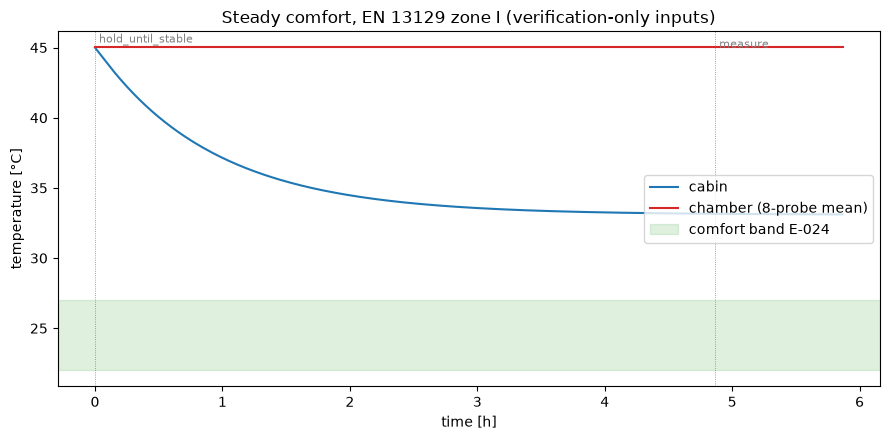

Steady comfort, EN 13129 zone I  [EN 13129:2016, to confirm]
facility: vehicle_chamber; sensors: evidence accuracies, seed 0
RESULT: FAIL

Measured:
  cabin_T_mean = 33.17 +/- 0.11 degC
  cabin_RH_mean = 0.526 +/- 0.02 -
  chamber_T_mean = 45.01 +/- 0.11 degC
Criteria:
  [FAIL] cabin mean temperature within the EN 13129 comfort band: cabin_T_mean in 24.5 +/- 2.5 degC
Evidence used (56): E-002, E-004, E-006, E-007, E-022, E-024, E-026, E-027, E-029, E-030, E-031, E-034, E-035, E-036, E-037, E-038, E-039, E-040, E-042, E-043, E-044, E-045, E-046, E-047, E-058, E-059, E-060, E-061, E-062, E-063, E-064, E-065, E-066, E-067, E-071, E-072, E-073, E-074, E-077, E-079, E-093, E-094, E-095, E-096, E-097, E-098, E-099, E-100, E-101, E-102, E-103, E-104, E-105, E-106, E-107, E-108
Assumptions / overrides (43):
  - E-002 Coach overall heat transfer coefficient (k-value) = 1.2 W/m2K (assumption)
  - E-026 Passenger sensible heat (split of E-025) = 70.0 W/person (assumption, verification-only)
  - E

In [4]:
comfort = run_procedure("comfort_en13129_zone1", coach=coach, unit_card=card, evidence=reg,
                        sensors="evidence", seed=SEED)
c, t = reg.get("E-024").value, reg.get("E-024").record.tolerance
plot(comfort, (c - t, c + t), "comfort band E-024", "Steady comfort, EN 13129 zone I (verification-only inputs)")
print(comfort.summary())

For contrast, the same unit in the EN 13129 zone II comfort test (E-023, 35 °C, solar E-078):

In [5]:
zone2 = run_procedure("comfort_en13129_zone2", coach=coach, unit_card=card, evidence=reg,
                      sensors="evidence", seed=SEED)
m = zone2.measurements["cabin_T_mean"]
print(f"zone II: cabin mean {m.value:.2f} ± {m.uncertainty:.2f} °C -> "
      f"{'PASS' if zone2.passed else 'FAIL'}")

zone II: cabin mean 24.43 ± 0.10 °C -> PASS
